# 02 · Probability quality: model vs book (S2, development windows)

Model and book probabilities are compared on **the same evaluation rows**, sampled at fixed times to close, against proxy outcomes. Probability quality only; trade economics are in notebook 03.

**Labels on every number.** Outcomes are `proxy_outcome` labels (single positive payout entry, payout unit unknown). K is PROVISIONAL (exact-start TWAP tick, no attestation). The reference is the warehouse PolyBolt TWAP, not live RTDS. Execution follows named, uncalibrated scenarios; fees are the scenario curve. These are small samples from three recording sessions: diagnostics, not validated profitability.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from tyrex_pm.research.strategy_lab import analysis, frames, plots
from tyrex_pm.research.strategy_lab.experiments import REPO, Lab

pd.set_option('display.width', 160)
S2 = REPO / 'var' / 'research' / 'strategy_runs' / 's2'
split = json.loads((S2 / 'split' / 'split.json').read_text())
print(len(split['development']), 'development windows;', len(split['holdout']),
      'holdout windows (not evaluated)')

45 development windows; 18 holdout windows (not evaluated)


**Data note.** The volatility experiment kept the decision-driving probability (`p_up_point`, endpoint backend) and the book midpoint. Its compact schema predated the per-backend columns, so the TWAP proxy is shown on one window further down, not pooled. Rerunning `s2_experiments vol` now records both backends.

In [2]:
decisions = pd.read_parquet(S2 / 'vol' / 'decisions.parquet')
decisions = decisions.rename(columns={'p_up_point': 'endpoint_p_up'})
rows = analysis.checkpoint_rows(decisions)
columns = ('endpoint_p_up', 'book_implied_up')
quality = analysis.flatten_config(analysis.probability_quality(rows, columns=columns))
print(rows['market_id'].nunique(), 'windows;', rows['config'].nunique(),
      'volatility configurations')

44 windows; 10 volatility configurations


## Brier score by checkpoint: book vs model (current seed and old floor)

Lower is better. `n` is the number of windows with both probabilities at that checkpoint (books are often unusable in the last minute).

In [3]:
base = quality[(quality['volatility.half_life_s'] == 30.0)
               & (quality['volatility.sigma_scale'] == 1.0)]
base.pivot_table(index=['checkpoint_s', 'source'],
                 columns='volatility.sigma_floor', values=['brier', 'n']).round(3)

brier               n        
volatility.sigma_floor       0.00001 0.00010 0.00001 0.00010
checkpoint_s source                                         
30.0         book_implied_up   0.012   0.012     2.0     2.0
             endpoint_p_up     0.306   0.234     2.0     2.0
60.0         book_implied_up   0.083   0.083    15.0    15.0
             endpoint_p_up     0.132   0.155    15.0    15.0
120.0        book_implied_up   0.166   0.166    33.0    33.0
             endpoint_p_up     0.196   0.189    33.0    33.0
180.0        book_implied_up   0.146   0.146    34.0    34.0
             endpoint_p_up     0.173   0.188    34.0    34.0
240.0        book_implied_up   0.161   0.161    38.0    38.0
             endpoint_p_up     0.197   0.199    38.0    38.0

## Volatility sensitivity of the model (Brier, all checkpoints pooled)

In [4]:
model = quality[quality['source'] == 'endpoint_p_up']
model.groupby(['volatility.sigma_floor', 'volatility.half_life_s',
               'volatility.sigma_scale'])[['brier', 'log_loss']].mean().round(4)

brier  log_loss
volatility.sigma_floor volatility.half_life_s volatility.sigma_scale                  
0.00001                15.0                   0.75                    0.2285    0.7371
                                              1.00                    0.2148    0.6402
                                              1.25                    0.2069    0.6029
                       30.0                   0.75                    0.2145    0.6449
                                              1.00                    0.2009    0.5835
                                              1.25                    0.1946    0.5642
                       60.0                   0.75                    0.2056    0.6127
                                              1.00                    0.1941    0.5660
                                              1.25                    0.1897    0.5542
0.00010                30.0                   1.00                    0.1928    0.5661

## Reliability at 120 s to close (current seed)

endpoint_p_up
               mean_predicted  observed_up   n
endpoint_p_up                                 
(-0.001, 0.2]           0.134        0.143   7
(0.2, 0.4]              0.343        0.167   6
(0.4, 0.6]              0.470        0.333   6
(0.6, 0.8]              0.793        1.000   2
(0.8, 1.0]              0.924        0.667  12
book_implied_up
                 mean_predicted  observed_up   n
book_implied_up                                 
(-0.001, 0.2]             0.073        0.100  10
(0.2, 0.4]                0.309        0.429   7
(0.4, 0.6]                0.477        0.000   3
(0.6, 0.8]                0.749        0.750   4
(0.8, 1.0]                0.909        0.778   9


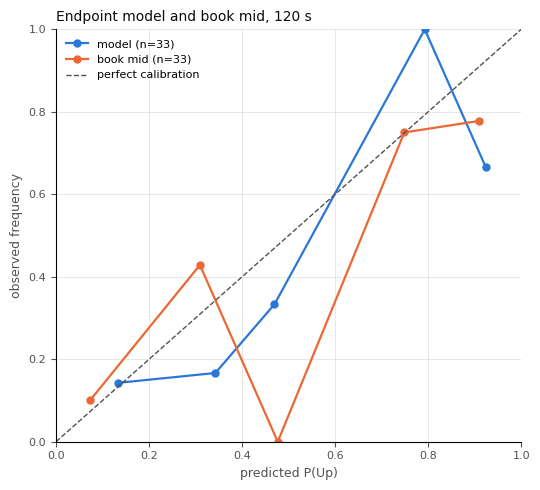

In [5]:
rows_flat = analysis.flatten_config(rows)
seed = rows_flat[(rows_flat['volatility.sigma_floor'] == 1e-5)
                 & (rows_flat['volatility.half_life_s'] == 30.0)
                 & (rows_flat['volatility.sigma_scale'] == 1.0)
                 & (rows_flat['checkpoint_s'] == 120.0)].dropna(subset=list(columns))
fig = plots.plot_reliability(seed.rename(columns={'endpoint_p_up': 'p_up_point'}),
                             bins=5, title='Endpoint model and book mid, 120 s')
for column in columns:
    print(column)
    print(analysis.reliability_table(seed, column).round(3))

## Endpoint vs TWAP proxy vs book on one development window (real driver)

Text(0.0, 1.0, '0923be1d1dc4')

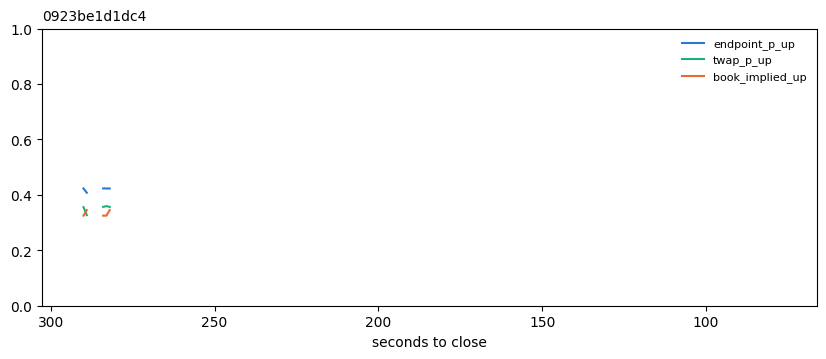

In [6]:
lab = Lab()
market = next(m for m in split['development'] if m in {w.market_id for w in lab.windows()})
one = frames.decisions(lab.run(market))
for column in ('endpoint_p_up', 'twap_p_up'):
    one[column] = pd.to_numeric(one.get(column), errors='coerce')
fig, ax = plt.subplots(figsize=(10, 3.6))
for column, color in (('endpoint_p_up', plots.BLUE), ('twap_p_up', plots.AQUA),
                      ('book_implied_up', plots.ORANGE)):
    ax.plot(one['t_minus_s'], one[column], color=color, lw=1.5, label=column)
ax.invert_xaxis()
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8)
ax.set_xlabel('seconds to close')
ax.set_title(market[-12:], loc='left', fontsize=10)

## Reading

* The book's own midpoint is the better probability at every checkpoint on these windows. The model therefore should not be trusted to disagree with the book without further evidence.
* Volatility settings move the model's Brier score only modestly; none closes the gap to the book.
* Sample sizes per checkpoint are 15–38 windows: differences of a few thousandths are not meaningful.